In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Input features:")
display(X.head())

print("Target house values:")
display(y.head())

print("X shape:", X.shape)
print("y shape:", y.shape)


Input features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


Target house values:


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


X shape: (20640, 8)
y shape: (20640,)


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 16512
Testing records: 4128


In [ ]:

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 3))
print("R2 Score:", round(r2, 3))


Mean Absolute Error: 0.328
R2 Score: 0.805


In [ ]:

new_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 25,
    "AveRooms": 5.0,
    "AveBedrms": 1.0,
    "Population": 1000,
    "AveOccup": 3.0,
    "Latitude": 34.0,
    "Longitude": -118.0
}])

predicted_value = model.predict(new_house)[0]

print("Predicted house value:",
      round(predicted_value, 3),
      "units of $100,000")

print("Approximate value in dollars:",
      "${:,.0f}".format(predicted_value * 100000))


Predicted house value: 2.094 units of $100,000
Approximate value in dollars: $209,428


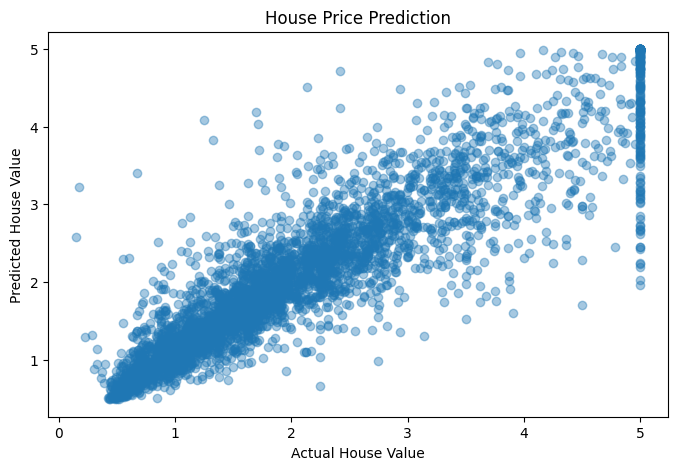

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("House Price Prediction")

plt.show()


In [ ]:

results = pd.DataFrame({
    "Actual Value": y_test.iloc[:10].values,
    "Predicted Value": y_pred[:10]
})

display(results.round(3))


,Actual Value,Predicted Value
0,0.477,0.509
1,0.458,0.742
2,5.000,4.923
3,2.186,2.530
4,2.780,2.274
5,1.587,1.647
6,1.982,2.376
7,1.575,1.669
8,3.400,2.773
9,4.466,4.913
